In [ ]:
!pip install --upgrade --force-reinstall numpy pandas scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.7/15.7 MB 57.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 80.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 79.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 83.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 78.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 68.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 64.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 76.6 MB/s  0:00:00
  Attempting uninstall: tzdata
    Found existing installation: tzdata 2026.6
    Uninstalling tzdata-2026.6:
      Successfully uninstalled tzdata-2026.6
  Attempting uninstall: threadpoolctl
    Found existing installation: threadpoolctl 3.7.0
    Uninstalling threadpoolctl-3.7.0:
      Successfully uninstalled threadpoolctl-3.7.0
  Attempting uninstall: pyparsing
    Found existing installation: 

=== CONFIGURACIÓN ESTABLECIDA ===
Frecuencia de Muestreo (Fs): 10000 Hz
Frecuencia Portadora (Fc): 1000 Hz
Muestras por símbolo: 100
Longitud de cada señal temporal: 2000 muestras

Generando el dataset de señales (esto tomará unos segundos)...
¡Dataset creado con éxito!
Dimensiones de la matriz de características (X): (4000, 2000)
Dimensiones del vector de etiquetas (y): (4000,)

--- DIVISIÓN DEL DATASET ---
Conjunto de Entrenamiento: 3200 muestras
Conjunto de Prueba:        800 muestras


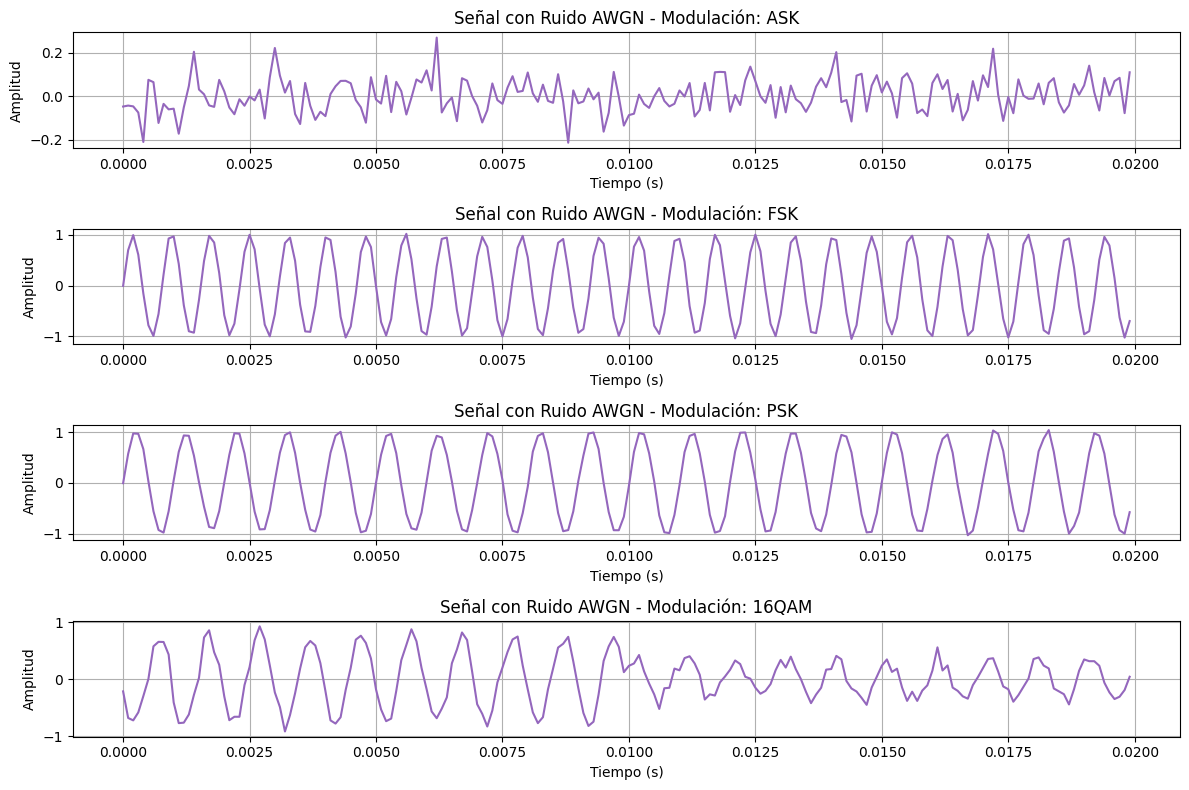

In [2]:
# =====================================================================
# FASE 1: Generación y Preparación de Datos
# Proyecto: "El Detective de Señales" - Clasificación de Modulaciones
# =====================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# ---------------------------------------------------------------------
# 1.1 y 1.2: Configuración del Entorno y Parámetros de la Señal
# ---------------------------------------------------------------------
np.random.seed(42)  # Para asegurar la reproducibilidad de los datos

Fs = 10000       # Frecuencia de muestreo (Hz) - Cumple con Nyquist
Fc = 1000        # Frecuencia portadora (Hz)
Rs = 100         # Tasa de símbolos (Baudios)
samples_per_symbol = int(Fs / Rs)  # Muestras por símbolo (100 puntos)
num_symbols = 20   # Símbolos por cada trama de señal
signal_length = num_symbols * samples_per_symbol

t = np.arange(signal_length) / Fs

print("=== CONFIGURACIÓN ESTABLECIDA ===")
print(f"Frecuencia de Muestreo (Fs): {Fs} Hz")
print(f"Frecuencia Portadora (Fc): {Fc} Hz")
print(f"Muestras por símbolo: {samples_per_symbol}")
print(f"Longitud de cada señal temporal: {signal_length} muestras\n")

# ---------------------------------------------------------------------
# 1.3: Programación de Generadores de Señales (Temas 3.1 y 3.2)
# ---------------------------------------------------------------------

def generate_ask(num_symbols, samples_per_symbol, Fc, Fs):
    """Genera modulación ASK (Amplitude Shift Keying)"""
    bits = np.random.randint(0, 2, num_symbols)
    symbol_signal = np.repeat(bits, samples_per_symbol)
    t_local = np.arange(len(symbol_signal)) / Fs
    carrier = np.sin(2 * np.pi * Fc * t_local)
    signal = symbol_signal * carrier
    return signal, bits

def generate_fsk(num_symbols, samples_per_symbol, Fc, Fs):
    """Genera modulación FSK (Frequency Shift Keying con 2 tonos)"""
    bits = np.random.randint(0, 2, num_symbols)
    symbol_signal = np.repeat(bits, samples_per_symbol)
    t_local = np.arange(len(symbol_signal)) / Fs

    f1 = Fc - 300  # Frecuencia para bit 0
    f2 = Fc + 300  # Frecuencia para bit 1
    freqs = np.where(symbol_signal == 1, f2, f1)

    signal = np.sin(2 * np.pi * freqs * t_local)
    return signal, bits

def generate_psk(num_symbols, samples_per_symbol, Fc, Fs):
    """Genera modulación BPSK (Phase Shift Keying)"""
    bits = np.random.randint(0, 2, num_symbols)
    phases = np.where(bits == 1, np.pi, 0.0)  # 0 y 180 grados
    symbol_signal = np.repeat(phases, samples_per_symbol)
    t_local = np.arange(len(symbol_signal)) / Fs

    signal = np.sin(2 * np.pi * Fc * t_local + symbol_signal)
    return signal, bits

def generate_qam16(num_symbols, samples_per_symbol, Fc, Fs):
    """Genera modulación 16-QAM (Cuadratura y Amplitud)"""
    levels = [-3, -1, 1, 3]
    I_symbols = np.random.choice(levels, num_symbols)
    Q_symbols = np.random.choice(levels, num_symbols)

    I_signal = np.repeat(I_symbols, samples_per_symbol)
    Q_signal = np.repeat(Q_symbols, samples_per_symbol)
    t_local = np.arange(len(I_signal)) / Fs

    # Combinación de portadoras en cuadratura (Coseno y Seno)
    signal = I_signal * np.cos(2 * np.pi * Fc * t_local) - Q_signal * np.sin(2 * np.pi * Fc * t_local)
    # Normalización de amplitud
    signal = signal / (np.max(np.abs(signal)) + 1e-9)
    return signal, (I_symbols, Q_symbols)

# ---------------------------------------------------------------------
# 1.5: Función para añadir Ruido Gaussiano Blanco Aditivo (AWGN)
# ---------------------------------------------------------------------
def add_awgn(signal, snr_db):
    """Añade ruido AWGN a la señal según una Relación Señal-Ruido (SNR) dada en dB"""
    signal_power = np.mean(signal ** 2)
    snr_linear = 10 ** (snr_db / 10)
    noise_power = signal_power / (snr_linear + 1e-9)
    noise = np.sqrt(noise_power) * np.random.normal(0, 1, len(signal))
    return signal + noise

# ---------------------------------------------------------------------
# 1.4: Generación del Conjunto de Datos (1,000 muestras por modulación)
# ---------------------------------------------------------------------
samples_per_class = 1000
classes = ['ASK', 'FSK', 'PSK', '16QAM']

X = []
y = []

print("Generando el dataset de señales (esto tomará unos segundos)...")
for mod_name in classes:
    for _ in range(samples_per_class):
        # Asignamos un nivel de ruido aleatorio (SNR entre 5 dB y 30 dB)
        snr_db = np.random.uniform(5, 30)

        if mod_name == 'ASK':
            sig, _ = generate_ask(num_symbols, samples_per_symbol, Fc, Fs)
        elif mod_name == 'FSK':
            sig, _ = generate_fsk(num_symbols, samples_per_symbol, Fc, Fs)
        elif mod_name == 'PSK':
            sig, _ = generate_psk(num_symbols, samples_per_symbol, Fc, Fs)
        elif mod_name == '16QAM':
            sig, _ = generate_qam16(num_symbols, samples_per_symbol, Fc, Fs)

        # Añadir el ruido simulando el canal de transmisión
        noisy_sig = add_awgn(sig, snr_db)

        X.append(noisy_sig)
        y.append(mod_name)

X = np.array(X)
y = np.array(y)

print(f"¡Dataset creado con éxito!")
print(f"Dimensiones de la matriz de características (X): {X.shape}")
print(f"Dimensiones del vector de etiquetas (y): {y.shape}")

# ---------------------------------------------------------------------
# 1.6: Separación de Datos (80% Entrenamiento, 20% Prueba)
# ---------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"\n--- DIVISIÓN DEL DATASET ---")
print(f"Conjunto de Entrenamiento: {X_train.shape[0]} muestras")
print(f"Conjunto de Prueba:        {X_test.shape[0]} muestras")

# ---------------------------------------------------------------------
# Opcional: Visualización rápida de las señales generadas con ruido
# ---------------------------------------------------------------------
plt.figure(figsize=(12, 8))
for i, mod_name in enumerate(classes):
    idx = np.where(y == mod_name)[0][0]
    plt.subplot(4, 1, i+1)
    plt.plot(t[:200], X[idx][:200], color='tab:purple')
    plt.title(f"Señal con Ruido AWGN - Modulación: {mod_name}")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Amplitud")
    plt.grid(True)
plt.tight_layout()
plt.show()

Clases codificadas: {np.str_('16QAM'): 0, np.str_('ASK'): 1, np.str_('FSK'): 2, np.str_('PSK'): 3}
Forma de X_train para CNN: (3200, 2000, 1)



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 2000, 32)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 1000, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 1000, 64)       │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 500, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,048,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,058,884 (7.85 MB)

 Trainable params: 2,058,884 (7.85 MB)

 Non-trainable params: 0 (0.00 B)


Iniciando entrenamiento de la Red Neuronal...
Epoch 1/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 79ms/step - accuracy: 0.9328 - loss: 0.1681 - val_accuracy: 1.0000 - val_loss: 3.6015e-04
Epoch 2/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 74ms/step - accuracy: 0.9991 - loss: 0.0043 - val_accuracy: 1.0000 - val_loss: 4.3712e-04
Epoch 3/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 74ms/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 1.0000 - val_loss: 2.4280e-05
Epoch 4/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 1.0000 - loss: 7.4362e-04 - val_accuracy: 1.0000 - val_loss: 8.4243e-06
Epoch 5/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 80ms/step - accuracy: 0.9994 - loss: 8.7174e-04 - val_accuracy: 1.0000 - val_loss: 1.6051e-04
Epoch 6/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 83ms/step - accuracy: 0.9997 - loss: 0.0013 - val_accuracy: 1.0000 - val_loss: 2.7040e-04
Epoch 7/15
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 72ms/step - accuracy: 1.0000 - loss: 4.4672e-04 - val_accuracy: 1.0000 - val_loss: 5.6924e-06
Epoch 8

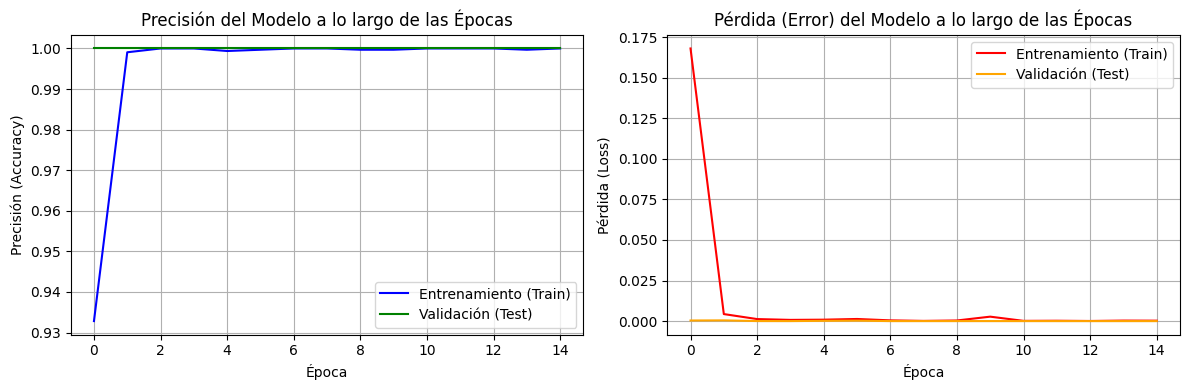

In [3]:
# =====================================================================
# FASE 2: Diseño y Entrenamiento del Modelo (Semana 2)
# Proyecto: "El Detective de Señales"
# =====================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical

# ---------------------------------------------------------------------
# 2.0: Preparación de los datos para la Red Neuronal (1D-CNN)
# ---------------------------------------------------------------------
# Convertir etiquetas de texto ('ASK', 'FSK', etc.) a números (0, 1, 2, 3) y luego a One-Hot Encoding
label_encoder = LabelEncoder()
y_train_num = label_encoder.fit_transform(y_train)
y_test_num = label_encoder.transform(y_test)

y_train_cat = to_categorical(y_train_num, num_classes=4)
y_test_cat = to_categorical(y_test_num, num_classes=4)

# Redimensionar X para Conv1D: (muestras, longitud_señal, 1 canal)
X_train_cnn = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
X_test_cnn = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))

print("Clases codificadas:", dict(zip(label_encoder.classes_, range(4))))
print(f"Forma de X_train para CNN: {X_train_cnn.shape}\n")

# ---------------------------------------------------------------------
# 2.2: Diseñar el Modelo (Arquitectura 1D-CNN)
# ---------------------------------------------------------------------
model = Sequential([
    # Capa de entrada que recibe la longitud de la señal (2000, 1)
    Input(shape=(signal_length, 1)),

    # Primer bloque convolucional para detectar patrones básicos de onda
    Conv1D(filters=32, kernel_size=7, activation='relu', padding='same'),
    MaxPooling1D(pool_size=2),

    # Segundo bloque convolucional para características más complejas
    Conv1D(filters=64, kernel_size=5, activation='relu', padding='same'),
    MaxPooling1D(pool_size=2),

    # Aplanamiento y capas densas de clasificación
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.3),  # Evita que la red memorice (overfitting)

    # Capa de salida con 4 neuronas (una por cada modulación) y Softmax
    Dense(4, activation='softmax')
])
# ---------------------------------------------------------------------
# 2.3: Compilar el Modelo
# ---------------------------------------------------------------------
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model.summary()
# ---------------------------------------------------------------------
# 2.4: Entrenar el Modelo (.fit)
# ---------------------------------------------------------------------
print("\nIniciando entrenamiento de la Red Neuronal...")
history = model.fit(
    X_train_cnn, y_train_cat,
    epochs=15,               # Número de pasadas completas por los datos
    batch_size=32,           # Muestras procesadas antes de actualizar pesos
    validation_data=(X_test_cnn, y_test_cat),
    verbose=1
)
# ---------------------------------------------------------------------
# 2.5: Guardar el Modelo Entrenado
# ---------------------------------------------------------------------
model_filename = 'detective_senales_cnn.keras'
model.save(model_filename)
print(f"\n¡Modelo guardado exitosamente como '{model_filename}'!")

# ---------------------------------------------------------------------
# Visualización del Entrenamiento (Precisión y Pérdida)
# ---------------------------------------------------------------------
plt.figure(figsize=(12, 4))
# Gráfica de Precisión (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Entrenamiento (Train)', color='blue')
plt.plot(history.history['val_accuracy'], label='Validación (Test)', color='green')
plt.title('Precisión del Modelo a lo largo de las Épocas')
plt.xlabel('Época')
plt.ylabel('Precisión (Accuracy)')
plt.legend()
plt.grid(True)
# Gráfica de Pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Entrenamiento (Train)', color='red')
plt.plot(history.history['val_loss'], label='Validación (Test)', color='orange')
plt.title('Pérdida (Error) del Modelo a lo largo de las Épocas')
plt.xlabel('Época')
plt.ylabel('Pérdida (Loss)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

<Figure size 700x600 with 0 Axes>

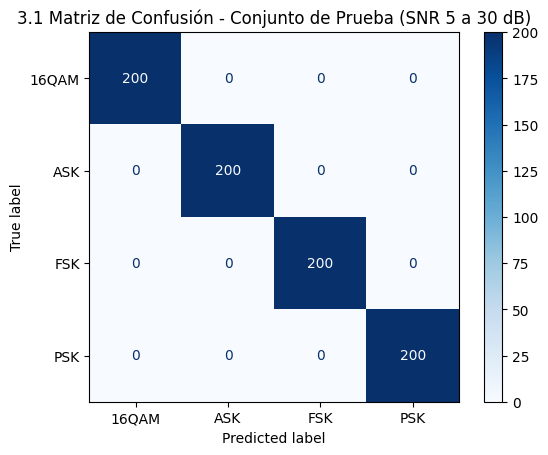

Precisión general en X_test (5 a 30 dB): 100.00%

=== PRUEBA DE ESTRÉS POR NIVEL DE SNR ===
SNR: -15 dB (Ruido alto / extremo (SNR bajo)) -> Precisión:  25.25%
SNR: -10 dB (Ruido alto / extremo (SNR bajo)) -> Precisión:  39.75%
SNR:  -5 dB (Ruido alto / extremo (SNR bajo)) -> Precisión:  81.12%
SNR:   0 dB (Ruido moderado (SNR medio)) -> Precisión:  99.38%
SNR:   5 dB (Ruido moderado (SNR medio)) -> Precisión: 100.00%
SNR:  10 dB (Ruido moderado (SNR medio)) -> Precisión: 100.00%
SNR:  15 dB (Señal limpia / poco ruido (SNR alto)) -> Precisión: 100.00%
SNR:  20 dB (Señal limpia / poco ruido (SNR alto)) -> Precisión: 100.00%
SNR:  25 dB (Señal limpia / poco ruido (SNR alto)) -> Precisión: 100.00%


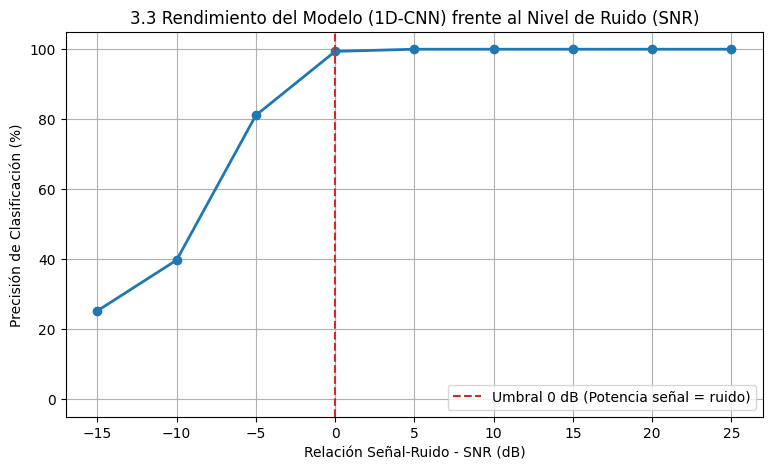


=== ANÁLISIS DE ERRORES A SNR = -5 dB (200 muestras por clase) ===
Modulación 16QAM : 200/200 aciertos |   0 errores (  0.0% de error)
Modulación ASK   : 140/200 aciertos |  60 errores ( 30.0% de error)
Modulación FSK   : 200/200 aciertos |   0 errores (  0.0% de error)
Modulación PSK   : 108/200 aciertos |  92 errores ( 46.0% de error)


In [4]:
# =====================================================================
# FASE 3: Evaluación y Robustez (Semana 3)
# Proyecto: "El Detective de Señales"
# =====================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# ---------------------------------------------------------------------
# 3.1: Matriz de Confusión sobre el conjunto de prueba (X_test_cnn)
# ---------------------------------------------------------------------
y_pred_probs = model.predict(X_test_cnn, verbose=0)
y_pred_num = np.argmax(y_pred_probs, axis=1)
y_true_num = y_test_num

cm = confusion_matrix(y_true_num, y_pred_num)
class_names = list(label_encoder.classes_)

plt.figure(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues', values_format='d')
plt.title("3.1 Matriz de Confusión - Conjunto de Prueba (SNR 5 a 30 dB)")
plt.grid(False)
plt.show()

acc_base = accuracy_score(y_true_num, y_pred_num)
print(f"Precisión general en X_test (5 a 30 dB): {acc_base * 100:.2f}%\n")

# ---------------------------------------------------------------------
# 3.2 y 3.3: Prueba de Estrés (Ruido) y Gráfica de Rendimiento vs SNR
# ---------------------------------------------------------------------
# Evaluamos desde ruido extremo (-15 dB) hasta señal limpia (+25 dB)
snr_levels = [-15, -10, -5, 0, 5, 10, 15, 20, 25]
accuracies_by_snr = []

# Generamos un lote de prueba limpio de 800 señales (200 por clase) para medir SNR exacto
X_clean_eval = []
y_clean_eval = []
samples_per_class_eval = 200

for mod_name in classes:
    for _ in range(samples_per_class_eval):
        if mod_name == 'ASK':
            sig, _ = generate_ask(num_symbols, samples_per_symbol, Fc, Fs)
        elif mod_name == 'FSK':
            sig, _ = generate_fsk(num_symbols, samples_per_symbol, Fc, Fs)
        elif mod_name == 'PSK':
            sig, _ = generate_psk(num_symbols, samples_per_symbol, Fc, Fs)
        elif mod_name == '16QAM':
            sig, _ = generate_qam16(num_symbols, samples_per_symbol, Fc, Fs)
        X_clean_eval.append(sig)
        y_clean_eval.append(mod_name)

X_clean_eval = np.array(X_clean_eval)
y_eval_num = label_encoder.transform(np.array(y_clean_eval))

print("=== PRUEBA DE ESTRÉS POR NIVEL DE SNR ===")
for snr in snr_levels:
    X_noisy_snr = np.array([add_awgn(s, snr) for s in X_clean_eval])
    X_noisy_cnn = X_noisy_snr.reshape((X_noisy_snr.shape[0], X_noisy_snr.shape[1], 1))

    preds = np.argmax(model.predict(X_noisy_cnn, verbose=0), axis=1)
    acc = accuracy_score(y_eval_num, preds)
    accuracies_by_snr.append(acc * 100)

    # Clasificación rápida del régimen de ruido para la bitácora
    if snr < 0:
        regimen = "Ruido alto / extremo (SNR bajo)"
    elif snr <= 10:
        regimen = "Ruido moderado (SNR medio)"
    else:
        regimen = "Señal limpia / poco ruido (SNR alto)"

    print(f"SNR: {snr:3d} dB ({regimen}) -> Precisión: {acc * 100:6.2f}%")

# Gráfica 3.3: SNR vs Precisión
plt.figure(figsize=(9, 5))
plt.plot(snr_levels, accuracies_by_snr, marker='o', linewidth=2, color='tab:blue')
plt.axvline(x=0, color='tab:red', linestyle='--', label='Umbral 0 dB (Potencia señal = ruido)')
plt.title("3.3 Rendimiento del Modelo (1D-CNN) frente al Nivel de Ruido (SNR)")
plt.xlabel("Relación Señal-Ruido - SNR (dB)")
plt.ylabel("Precisión de Clasificación (%)")
plt.ylim(-5, 105)
plt.grid(True)
plt.legend()
plt.show()

# ---------------------------------------------------------------------
# 3.4: Análisis de Errores por Modulación (a SNR = -5 dB para forzar fallos)
# ---------------------------------------------------------------------
X_stress = np.array([add_awgn(s, -5) for s in X_clean_eval])
X_stress_cnn = X_stress.reshape((X_stress.shape[0], X_stress.shape[1], 1))
y_stress_pred = np.argmax(model.predict(X_stress_cnn, verbose=0), axis=1)

print("\n=== ANÁLISIS DE ERRORES A SNR = -5 dB (200 muestras por clase) ===")
for idx, cname in enumerate(class_names):
    mask = (y_eval_num == idx)
    total_c = np.sum(mask)
    correct_c = np.sum(y_stress_pred[mask] == idx)
    errors_c = total_c - correct_c
    err_rate = (errors_c / total_c) * 100
    print(f"Modulación {cname:6s}: {correct_c:3d}/{total_c} aciertos | {errors_c:3d} errores ({err_rate:5.1f}% de error)")

(Dato interno de control -> Modulación real generada: 16QAM)

=== RESULTADO: Señal Nueva Aleatoria ===
Ruido aplicado: SNR = 13.377780777849148 dB
Modulación detectada: 16QAM (100.00% de confianza)
Probabilidades por clase:
  - 16QAM : 100.00%
  - ASK   :   0.00%
  - FSK   :   0.00%
  - PSK   :   0.00%


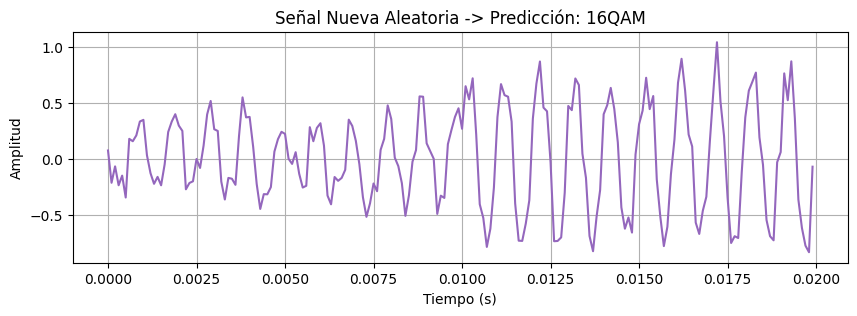

(np.str_('16QAM'),
 array([1.0000000e+00, 1.1526940e-14, 2.1959795e-16, 3.2836340e-09],
       dtype=float32))

In [42]:
# =====================================================================
# DEMOSTRACIÓN EN VIVO: Clasificar una señal nueva en la exposición Al azar
# =====================================================================

def clasificar_senal_nueva(senal_1d, snr_db=None, titulo="Señal de Prueba"):
    """
    Recibe un arreglo 1D de longitud signal_length (2000 muestras),
    opcionalmente le añade ruido AWGN en dB, la pasa al modelo entrenado
    y muestra la predicción y probabilidades.
    """
    senal = np.array(senal_1d, dtype=np.float32).flatten()

    # Verificar longitud esperada por la red (2000 muestras)
    if len(senal) != signal_length:
        print(f"Aviso: la señal tiene {len(senal)} muestras; se esperaban {signal_length}.")
        if len(senal) > signal_length:
            senal = senal[:signal_length]
        else:
            senal = np.pad(senal, (0, signal_length - len(senal)))


    if snr_db is not None:
        senal = add_awgn(senal, snr_db)

    # Dar la forma exacta que espera la 1D-CNN: (1, 2000, 1)
    entrada_cnn = senal.reshape((1, signal_length, 1))

    # Predicción
    probs = model.predict(entrada_cnn, verbose=0)[0]
    idx_pred = np.argmax(probs)
    clase_pred = label_encoder.classes_[idx_pred]

    print(f"=== RESULTADO: {titulo} ===")
    if snr_db is not None:
        print(f"Ruido aplicado: SNR = {snr_db} dB")
    print(f"Modulación detectada: {clase_pred} ({probs[idx_pred]*100:.2f}% de confianza)")
    print("Probabilidades por clase:")
    for nombre, p in zip(label_encoder.classes_, probs):
        print(f"  - {nombre:6s}: {p*100:6.2f}%")

    # Graficar un fragmento para visualizar
    plt.figure(figsize=(10, 3))
    plt.plot(t[:200], senal[:200], color='tab:purple')
    plt.title(f"{titulo} -> Predicción: {clase_pred}")
    plt.xlabel("Tiempo (s)")
    plt.ylabel("Amplitud")
    plt.grid(True)
    plt.show()

    return clase_pred, probs

# --- Ejemplo rápido: generar una señal nueva al azar y probarla ---
tipo_real = np.random.choice(classes)
snr_prueba = np.random.uniform(5, 25)

if tipo_real == 'ASK':
    sig_nueva, _ = generate_ask(num_symbols, samples_per_symbol, Fc, Fs)
elif tipo_real == 'FSK':
    sig_nueva, _ = generate_fsk(num_symbols, samples_per_symbol, Fc, Fs)
elif tipo_real == 'PSK':
    sig_nueva, _ = generate_psk(num_symbols, samples_per_symbol, Fc, Fs)
else:
    sig_nueva, _ = generate_qam16(num_symbols, samples_per_symbol, Fc, Fs)

print(f"(Dato interno de control -> Modulación real generada: {tipo_real})\n")
clasificar_senal_nueva(sig_nueva, snr_db=snr_prueba, titulo="Señal Nueva Aleatoria")


=== RESULTADO: Prueba ___ ===
Ruido aplicado: SNR = 50 dB
Modulación detectada: ASK (100.00% de confianza)
Probabilidades por clase:
  - 16QAM :   0.00%
  - ASK   : 100.00%
  - FSK   :   0.00%
  - PSK   :   0.00%


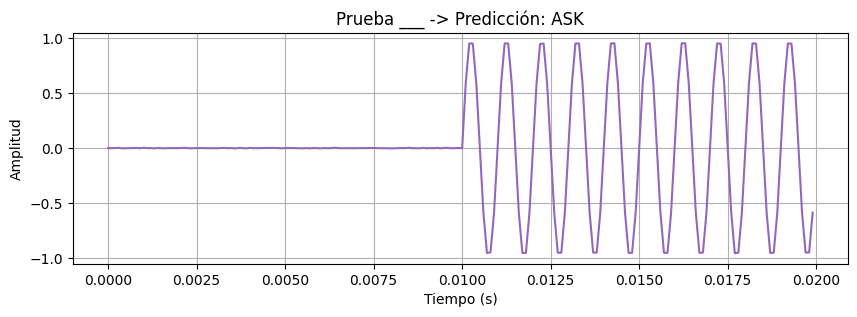

(np.str_('ASK'),
 array([3.3611230e-10, 1.0000000e+00, 4.6793047e-12, 8.1458529e-12],
       dtype=float32))

In [47]:
# --- Prueba una señal ___ con ruido de __ ---
sig_nueva, _ = generate_ask(num_symbols, samples_per_symbol, Fc, Fs)
clasificar_senal_nueva(sig_nueva, snr_db=50, titulo="Prueba ___")